# Trabajo Práctico 3 de Programación Orientada al Análisis de Datos

IES 9-008 Manuel Belgrano, Mendoza, Argentina. 2° 4. Ciclo lectivo 2026. Prof. Lic. Juan Caballero.

Estudiante: Franco Ciccarelli

Debido a que el Trabajo Practico lo realizo individualmente, los DNI de los demas "estudiantes" se inventaron.

- Franco Ciccarelli, DNI: 43418091
- Martin Palermo, DNI: 40678543
- Novak Djokovic, DNI: 37665411
- Gaston Gaudio, DNI: 42912018


In [2]:
import numpy
from pandas import DataFrame
from scipy import stats
import statsmodels.formula.api as smf
from tabulate import tabulate

## 1. Tomen los últimos 3 dígitos de sus DNI y súmenlos para generar una semilla. Por ejemplo, estudiantes con DNI 12.345.678 y 98.765.432 suman 678 + 432. (2 puntos)

In [ ]:
FRANCO_CICCARELLI = 43418091
MARTIN_PALERMO = 40678543
NOVAK_DJOKOVIC = 37665411
GASTON_GAUDIO = 42912018

def stringizador(nombre):
    return str(nombre)

# stringizador(FRANCO_CICCARELLI)[7:]

'1'

In [ ]:
SEMILLA = stringizador(FRANCO_CICCARELLI)[5:] + stringizador(MARTIN_PALERMO)[5:] + stringizador(NOVAK_DJOKOVIC)[5:] + stringizador(GASTON_GAUDIO)[5:]
RANGO = numpy.random.default_rng(seed=int(SEMILLA))
print("Semilla: ", SEMILLA)

Semilla:  091543411018


## 2. Tomen tercer, cuarto y quinto dígitos de sus DNI y súmenlos para generar un tamaño de población mayor a 1000. Por ejemplo, estudiantes con DNI 12.345.678 y 98.765.432 suman 345 + 765. (2 puntos)

In [30]:
N_POBLACION = 1000 + int(stringizador(FRANCO_CICCARELLI)[2:5]) + int(stringizador(MARTIN_PALERMO)[2:5]) + int(stringizador(NOVAK_DJOKOVIC)[2:5]) + int(stringizador(GASTON_GAUDIO)[2:5])
print("Tamaño de población:", N_POBLACION)

Tamaño de población: 3673


No hay tiempo para que generen datos ficticios o consumamos fuentes externas. Como esto ya lo hicieron en el Trabajo Práctico 2, acá lo tienen hecho.

In [31]:
NOMBRES = DataFrame([ ("Homero", "M"), ("Elvira", "F"), ("Gothik", "M"), ("Lassia", "F"), ("Bella", "F"), ("Mortimer", "M"), ("Alexander", "M"),
("Cassandra", "F"), ("Bebula", "F"), ("Leon", "M"), ("Manolo", "M"), ("Elvira", "F"), ("Celia", "F"), ("Daniel", "M"), ("Maria", "F"), ("Angela", "F"),
("Lilia", "F"), ("Juan", "M"), ("Verónica", "F"), ("Begoña", "F"), ("Mauricio", "M"), ("Guillermo", "M"), ("Don", "M"), ("Lothario", "M"),
("Dina", "F"), ("Nina", "F"), ("Darren", "M"), ("Dirk", "M"), ("Dustin", "M"), ("Brandi", "F"), ("Beau", "M"), ("Skip", "M"), ("Michael", "M"),
("Sonia", "F"), ("Pacomio", "M"), ("Pascual", "M"), ("Lázaro", "M"), ("Vicente", "M"), ("Aglaya", "F"), ("Circe", "F"), ("Loki", "M"),
("Nervioso", "M"), ("Poli", "M"), ("Jenny", "F"), ("Johnny", "M"), ("Jill", "F"), ("Cloe", "F"), ("Lola", "F"), ("Ofelia", "F"), ("Oliva", "F"),
("Súbdito", "M"), ("Titania", "F"), ("Oberón", "M"), ("Puck", "M"), ("Flor", "F"), ("Mercucio", "M"), ("Romeo", "M"), ("Teobaldo", "M"),
("Julieta", "F"), ("Hermia", "F"), ("Consorte", "M"), ("Regan", "F"), ("Goneril", "F"), ("Albany", "M"), ("Tybalt", "M"), ("Ophelia", "F"),
("Cordelia", "F") ], columns=["Nombre", "Genero"])

APELLIDOS = numpy.array([ "Lápiz", "Lothario", "Caliente", "Soñador", "Gentil", "Mancebo", "Novato", "Bueno", "Tenorio", "Matufo", "Del Solar", "Goth",
"Pleasant", "Burb", "Oldie", "Broke", "Curioso", "Beaker", "Del Riego", "Muñiz", "Singular", "Pérez", "Fantoche", "Nigromante", "Smith", "Subject",
"Monstruo", "Siniestro", "Alien", "Capuleto", "Montesco", "Duende", "Verona", "Montecchi", "Capulet", "Monty", "Summerdream" ])

EMPLEOS = DataFrame([ ("Caddie de Golf", 126, "Atleta"), ("Entrenador de Pistas", 154, "Atleta"),
("Entrenador Personal", 210, "Atleta"), ("Jugador Principiante", 252, "Atleta"), ("Titular de la Liga", 385, "Atleta"),
("Estelar All-Star", 570, "Atleta"), ("Jugador Más Valioso (MVP)", 1125, "Atleta"), ("Entrenador Principal", 1480, "Atleta"),
("Comisionado de la Liga", 1960, "Atleta"), ("Miembro del Salón de la Fama", 3033, "Atleta"), ("Repartidor de Correo", 168, "Negocios"),
("Asistente Ejecutivo", 252, "Negocios"), ("Comprador Junior", 350, "Negocios"), ("Gerente de Ventas", 441, "Negocios"),
("Vicepresidente Junior", 500, "Negocios"), ("Vicepresidente Senior", 560, "Negocios"), ("Director Ejecutivo (CEO)", 715, "Negocios"),
("Presidente del Consejo", 980, "Negocios"), ("Inversor de Riesgo", 1312, "Negocios"), ("Magnate de los Negocios", 2100, "Negocios"),
("Carterista", 168, "Criminal"), ("Ladrón de Poca Monta", 240, "Criminal"), ("Conductor de Huida", 315, "Criminal"),
("Perito de Seguros Falso", 400, "Criminal"), ("Falsificador", 475, "Criminal"), ("Contrabandista", 550, "Criminal"),
("Jefe de Banda", 625, "Criminal"), ("Asaltante Bancario", 850, "Criminal"), ("Asesino a Sueldo", 1100, "Criminal"),
("Mente Maestra del Crimen", 1925, "Criminal"), ("Lavaplatos", 126, "Cocina"), ("Cortador de Verduras", 168, "Cocina"),
("Cocinero de Comida Rápida", 182, "Cocina"), ("Cocinero de Línea", 242, "Cocina"), ("Chef de Repostero", 320, "Cocina"),
("Sous Chef", 410, "Cocina"), ("Chef de Cocina", 570, "Cocina"), ("Restaurador", 850, "Cocina"), ("Crítico Gastronómico", 1080, "Cocina"),
("Chef de Renombre Mundial", 2170, "Cocina"), ("Recluta", 350, "Fuerzas Armadas"), ("Cadete de Instrucción", 400, "Fuerzas Armadas"),
("Paracaidista", 450, "Fuerzas Armadas"), ("Instructor de Vuelo", 500, "Fuerzas Armadas"), ("Oficial de Operaciones", 575, "Fuerzas Armadas"),
("Piloto de Caza", 650, "Fuerzas Armadas"), ("Comandante de Base", 725, "Fuerzas Armadas"), ("Oficial Superior", 850, "Fuerzas Armadas"),
("Astronauta", 1225, "Fuerzas Armadas"), ("General de 5 Estrellas", 2288, "Fuerzas Armadas"), ("Técnico de Emergencias (EMT)", 280, "Medicina"),
("Paramédico", 385, "Medicina"), ("Médico Residente", 476, "Medicina"), ("Cirujano General", 574, "Medicina"),
("Investigador Médico", 672, "Medicina"), ("Especialista en Oncología", 770, "Medicina"), ("Cirujano Plástico", 875, "Medicina"),
("Director de Pediatría", 980, "Medicina"), ("Investigador del Genoma", 1190, "Medicina"), ("Jefe de Cirugía", 2333, "Medicina"),
("Recaudador de Votos", 308, "Política"), ("Becario Político", 350, "Política"), ("Asistente de Campaña", 420, "Política"),
("Asesor Municipal", 504, "Política"), ("Concejal", 602, "Política"), ("Representante del Estado", 672, "Política"), ("Congresista", 784, "Política"),
("Senador", 910, "Política"), ("Vicepresidente", 1225, "Política"), ("Alcalde / Presidente", 1313, "Política"),
("Limpiador de Tubos de Ensayo", 217, "Ciencia"), ("Técnico de Laboratorio", 322, "Ciencia"), ("Becario de Investigación", 385, "Ciencia"),
("Geólogo", 490, "Ciencia"), ("Químico de Alimentos", 595, "Ciencia"), ("Biólogo Marino", 665, "Ciencia"), ("Investigador de Fusión", 735, "Ciencia"),
("Experto en Robótica", 875, "Ciencia"), ("Investigador de Extraterrestres", 1050, "Ciencia"), ("Científico Loco", 2333, "Ciencia"),
("Guarda de Tráfico", 336, "Fuerzas de Seguridad"), ("Agente de Patrulla", 448, "Fuerzas de Seguridad"),
("Instructor de Tiro", 546, "Fuerzas de Seguridad"), ("Detective de Homicidios", 616, "Fuerzas de Seguridad"),
("Agente Encubierto", 686, "Fuerzas de Seguridad"), ("Agente del SWAT", 756, "Fuerzas de Seguridad"), ("Agente del FBI", 826, "Fuerzas de Seguridad"),
("Investigador Forense", 896, "Fuerzas de Seguridad"), ("Espía Internacional", 1015, "Fuerzas de Seguridad"),
("Comisionado de Policía", 1225, "Fuerzas de Seguridad"), ("Comprador de Discos", 91, "Gandul"), ("Dependiente de Gasolinera", 126, "Gandul"),
("Proyeccionista de Cine", 182, "Gandul"), ("DJ de Bar", 245, "Gandul"), ("Escultor de Hielo", 315, "Gandul"),
("Entrenador de Delfines", 385, "Gandul"), ("Fotógrafo de Moda", 455, "Gandul"), ("Diseñador de Videojuegos", 560, "Gandul"),
("Organizador de Fiestas", 700, "Gandul"), ("Icono Profesional", 1400, "Gandul") ], columns=["Cargo", "Sueldo", "Rubro"])

EMPLEOS["Nivel"] = EMPLEOS.groupby("Rubro").cumcount() + 1

Hagamos que cada persona tenga 2 nombres de pila acordes a su género y 2 apellidos.

In [32]:
GENEROS_POBLACION = RANGO.choice(["F", "M"], size=N_POBLACION)
NOMBRES_POBLACION = numpy.where(
    GENEROS_POBLACION == "F",
    [f"{n1} {n2}" for n1, n2 in zip(RANGO.choice(NOMBRES[NOMBRES["Genero"] == "F"]["Nombre"], size=N_POBLACION),
        RANGO.choice(NOMBRES[NOMBRES["Genero"] == "F"]["Nombre"], size=N_POBLACION))],
    [f"{n1} {n2}" for n1, n2 in zip(RANGO.choice(NOMBRES[NOMBRES["Genero"] == "M"]["Nombre"], size=N_POBLACION),
        RANGO.choice(NOMBRES[NOMBRES["Genero"] == "M"]["Nombre"], size=N_POBLACION))]
)
APELLIDOS_POBLACION = [f"{a1} {a2}" for a1, a2 in zip(RANGO.choice(APELLIDOS, size=N_POBLACION), RANGO.choice(APELLIDOS, size=N_POBLACION))]

En una sociedad no todos pueden ser gerentes. Para que la población esté empleada en pirámide, apliquemos la ley de Zipf.

In [33]:
def ley_de_zipf(coleccion: DataFrame, cantidad: int) -> DataFrame:
    niveles = coleccion["Nivel"].to_numpy()
    pesos_zipf = 1.0 / niveles
    probabilidades = pesos_zipf / pesos_zipf.sum()
    indices = RANGO.choice(len(coleccion), size=cantidad, p=probabilidades)
    return coleccion.iloc[indices].reset_index(drop=True)

EMPLEOS_POBLACION = ley_de_zipf(EMPLEOS, N_POBLACION)

def validar_zipf(df: DataFrame):
    niveles = numpy.sort(EMPLEOS["Nivel"].unique())
    d = (df["Nivel"].value_counts().reindex(niveles, fill_value=0).rename_axis("Nivel").reset_index(name="cantidad"))
    print(d.to_string(index=False))
    d = d[d["cantidad"] > 0]
    ajuste = stats.linregress(numpy.log(d["Nivel"]), numpy.log(d["cantidad"]))
    print(f"Exponente: {-ajuste.slope:.3f}")
    print(f"R²: {ajuste.rvalue**2:.3f}")
    if abs(1 - abs(ajuste.slope)) < 0.2 and ajuste.rvalue**2 > 0.8:
        print("Parece que sí sigue la ley de Zipf.")

validar_zipf(EMPLEOS_POBLACION)

 Nivel  cantidad
     1      1300
     2       596
     3       406
     4       312
     5       244
     6       200
     7       196
     8       163
     9       135
    10       121
Exponente: 1.001
R²: 0.996
Parece que sí sigue la ley de Zipf.


Imaginemos que es una población del primer mundo. Los hombres tienen mayor IMC cuanto más clase media sean. Las mujeres, mayor IMC cuanto más pobres.

#* anotaciones propias para entender:

MUJERES - idea sociológica: En países del primer mundo, los sectores de menores ingresos suelen tener dietas con comida ultraprocesada más barata y calórica, mientras que los sectores de mayores ingresos tienen más acceso a comida orgánica, dietas balanceadas, gimnasios, etc.

HOMBRES - idea sociológica: Los de menores ingresos tienen trabajos de esfuerzo físico (queman calorías). La clase media suele tener trabajos sedentarios de oficina combinados con abundancia de comida (sube el IMC). Los de ingresos muy altos vuelven a cuidarse más.

In [34]:
def generar_estaturas_pesos(sueldos: numpy.array, generos: numpy.array) -> tuple[numpy.array, numpy.array]:
    N = len(sueldos)
    s_norm = (sueldos - sueldos.min()) / (sueldos.max() - sueldos.min())
    imc_m = 24.0 + 4.5 * numpy.sin(numpy.pi * s_norm) + RANGO.normal(0, 0.5, size=N)
    imc_f = 28.0 - 5.0 * (s_norm ** 0.7) + RANGO.normal(0, 0.5, size=N)
    imc = numpy.where(generos == "M", imc_m, imc_f)
    estaturas = numpy.where(generos == "M", RANGO.normal(1.75, 0.07, size=N), RANGO.normal(1.63, 0.06, size=N))
    pesos = imc * (estaturas ** 2)
    return (estaturas, pesos)

ESTATURAS_POBLACION, PESOS_POBLACION = generar_estaturas_pesos(EMPLEOS_POBLACION["Sueldo"], GENEROS_POBLACION)

Ahora sí, les termino de armar la población para que sigamos con el trabajo práctico. Gracias por la paciencia.

In [35]:
POBLACION = DataFrame({
    "Apellido": APELLIDOS_POBLACION,
    "Nombre": NOMBRES_POBLACION,
    "Género": GENEROS_POBLACION,
    "Estatura": numpy.round(ESTATURAS_POBLACION, 2),
    "Peso": numpy.round(PESOS_POBLACION, 3),
    "Empleo": EMPLEOS_POBLACION["Cargo"],
    "Sueldo": EMPLEOS_POBLACION["Sueldo"],
    "Rubro": EMPLEOS_POBLACION["Rubro"],
    "Nivel": EMPLEOS_POBLACION["Nivel"]
})

POBLACION

,Apellido,Nombre,Género,Estatura,Peso,Empleo,Sueldo,Rubro,Nivel
0,Gentil Montesco,Don Lázaro,M,1.76,79.213,Vicepresidente Senior,560,Negocios,6
1,Lápiz Broke,Elvira Angela,F,1.68,74.371,Congresista,784,Política,7
2,Nigromante Muñiz,Angela Sonia,F,1.57,65.867,Becario de Investigación,385,Ciencia,3
3,Goth Bueno,Flor Cordelia,F,1.59,66.894,Comprador Junior,350,Negocios,3
4,Burb Fantoche,Skip Mortimer,M,1.72,74.798,Becario Político,350,Política,2
...,...,...,...,...,...,...,...,...,...
3668,Summerdream Broke,Dustin Skip,M,1.69,74.600,Fotógrafo de Moda,455,Gandul,7
3669,Pérez Singular,Angela Ofelia,F,1.70,79.212,Conductor de Huida,315,Criminal,3
3670,Broke Caliente,Circe Maria,F,1.52,63.982,Repartidor de Correo,168,Negocios,1
3671,Caliente Nigromante,Teobaldo Mauricio,M,1.68,70.565,Técnico de Laboratorio,322,Ciencia,2


## 3. Completen el siguiente código de correlación y regresión. (2 puntos)

Para que no se pierdan, muestro la lógica de la función a completar.
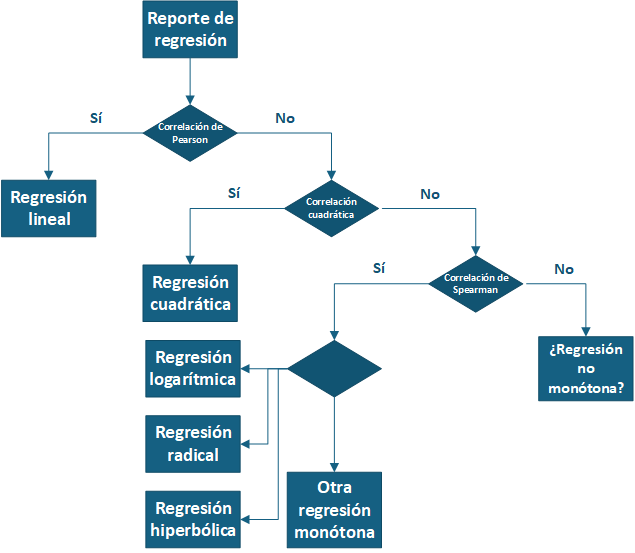

In [36]:
POBLACION["IMC"] = POBLACION["Peso"] / POBLACION["Estatura"] ** 2

def reportar_regresion(genero: str, campo_x: str, campo_y: str):
  print(tabulate([[f"-->     --> GÉNERO {genero}, X {campo_x}, Y {campo_y} <--     <--"]],tablefmt="grid"))
  corr, p = tuple(stats.pearsonr(POBLACION[POBLACION['Género']==genero][campo_x], POBLACION[POBLACION['Género']==genero][campo_y]))
  if abs(corr) >= 0.7 and p < 0.05:
    print("Detectada correlación lineal.")
    print(smf.ols(f"{campo_y} ~ {campo_x}", data=POBLACION[POBLACION['Género']==genero]).fit().summary())
  else:
    print(f"No hay correlación lineal.")
    hipotesis_cuadratica = smf.ols(f"{campo_y} ~ {campo_x} + I({campo_x}**2)", data=POBLACION[POBLACION['Género']==genero]).fit()
    if hipotesis_cuadratica.pvalues.iloc[-1] < 0.05:
      print("Detectada correlación cuadrática.")
      print(hipotesis_cuadratica.summary())
    else:
      print(f"No hay correlación cuadrática.")
      corr, p = tuple(stats.spearmanr(POBLACION[POBLACION['Género']==genero][campo_x], POBLACION[POBLACION['Género']==genero][campo_y]))
      if abs(corr) >= 0.7 and p < 0.05:
        if (POBLACION[POBLACION['Género']==genero][campo_x] <= 0).any():
          print("Error en el ajuste monótono por dominio negativo o nulo.")
        else:
          hipotesis = {"logaritmo": f"{campo_y} ~ log({campo_x})", "raíz": f"{campo_y} ~ I({campo_x}**0.5)",
                       "hipérbole": f"{campo_y} ~ I(1 / {campo_x})"}
          for ajuste, correlacion in hipotesis.items():
            modelo = smf.ols(correlacion, data=POBLACION[POBLACION['Género']==genero]).fit()
            if modelo.pvalues.iloc[-1] < 0.05:
              print(f"Detectada correlación monótona mediante {ajuste}.")
              print(modelo.summary())
              break
          else:
            print("Hay correlación monótona, pero no es una de las previstas.")
      else:
        print(f"No hay correlación monótona.")

reportar_regresion("F", "Sueldo", "IMC")
reportar_regresion("F", "Sueldo", "Peso")
reportar_regresion("F", "Sueldo", "Estatura")
reportar_regresion("M", "Sueldo", "IMC")
reportar_regresion("M", "Sueldo", "Peso")
reportar_regresion("M", "Sueldo", "Estatura")

+---------------------------------------------------+
| -->     --> GÉNERO F, X Sueldo, Y IMC <--     <-- |
+---------------------------------------------------+
Detectada correlación lineal.
                            OLS Regression Results                            
Dep. Variable:                    IMC   R-squared:                       0.673
Model:                            OLS   Adj. R-squared:                  0.673
Method:                 Least Squares   F-statistic:                     3724.
Date:                Fri, 23 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:59:54   Log-Likelihood:                -1367.3
No. Observations:                1810   AIC:                             2739.
Df Residuals:                    1808   BIC:                             2750.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 c

## 4. Programe las siguientes probabilidades. Recuerden usar la función len() y no size. (2 puntos)

Probabilidad de que una persona de la población sea mujer.

In [37]:
P_MUJER = len(POBLACION[POBLACION['Género']=='F']) / len(POBLACION)
print(f"P(mujer) = {P_MUJER * 100:.2f}%")

P(mujer) = 49.28%


Probabilidad de que una persona de la población esté bajo la línea de pobreza o en la cima de su carrera profesional. Para inventar la línea de pobreza, sumen el último dígito del DNI de cada estudiante.

In [ ]:
LINEA_DE_POBREZA = POBLACION['Sueldo'].max() / 100 * (int(stringizador(FRANCO_CICCARELLI)[7:]) + int(stringizador(MARTIN_PALERMO)[7:]) + int(stringizador(NOVAK_DJOKOVIC)[7:]) + int(stringizador(GASTON_GAUDIO)[7:]))
print(f"Línea de pobreza: ${LINEA_DE_POBREZA}")

P_POBRE = len(POBLACION[POBLACION['Sueldo'] <= LINEA_DE_POBREZA]) / len(POBLACION)
print(f"P(pobre) = {P_POBRE * 100:.2f}%")

P_N10 = len(POBLACION[POBLACION['Nivel'] == '10']) / len(POBLACION)
print(f"P(cima) = {P_N10 * 100:.2f}%")

P_POBRE_O_N10 = len(POBLACION[(POBLACION['Sueldo'] <= LINEA_DE_POBREZA) | (POBLACION['Nivel'] == 10)]) / len(POBLACION)
print(f"P(pobre o cima) = {P_POBRE_O_N10 * 100:.2f}%")

Línea de pobreza: $394.28999999999996
P(pobre) = 59.98%
P(cima) = 0.00%
P(pobre o cima) = 63.27%


Probabilidad de que una persona sea hombre o mida por debajo de 1.65 metro. Pista: para completar la regla de la suma, conviene usar dataframe[(condicion1) & (condicion2)].

In [ ]:
P_HOMBRE = len(POBLACION[POBLACION['Género']=='M']) / len(POBLACION)
print(f"P(hombre) = {P_HOMBRE * 100:.2f}%")

P_PETISO = len(POBLACION[POBLACION['Estatura'] <= 1.65]) / len(POBLACION)
print(f"P(petiso) = {P_PETISO * 100:.2f}%")

P_HOMBRE_Y_PETISO = len(POBLACION[(POBLACION['Género']=='M') & (POBLACION['Estatura'] <= 1.65)]) / len(POBLACION)
print(f"P(hombre y petiso) = {P_HOMBRE_Y_PETISO * 100:.2f}%")

P_HOMBRE_O_PETISO = (P_HOMBRE + P_PETISO) - P_HOMBRE_Y_PETISO / len(POBLACION)
print(f"P(hombre o petiso) = {P_HOMBRE_O_PETISO * 100:.2f}%")

P(hombre) = 50.72%
P(petiso) = 36.18%
P(hombre y petiso) = 4.14%
P(hombre o petiso) = 86.90%


Probabilidad de que una persona trabaje en el rubro de la ciencia y lanzar un dado icosaedro dé 19.

In [53]:
P_CIENTIFICO = len(POBLACION[POBLACION['Rubro'] == 'Ciencia']) / len(POBLACION)
print(f"P(científica) = {P_CIENTIFICO * 100:.2f}%")

#* anotacion propia: dado icosaedro es un dado de 20 caras
ICOSAEDRO = numpy.arange(0, 20)
P_19 = len(ICOSAEDRO[ICOSAEDRO == 19]) / len(ICOSAEDRO)
print(f"P(19) = {P_19 * 100:.2f}%")

#* YA QUe son eventos independientes se multiplican, no se suman. Corresponden a distintas "poblaciones"
P_CIENTIFICO_Y_19 = P_CIENTIFICO * P_19
print(f"P(científica y 19) = {P_CIENTIFICO_Y_19 * 100:.2f}%")

P(científica) = 9.86%
P(19) = 5.00%
P(científica y 19) = 0.49%


## 5. Muestreen y calculen. (2 puntos)

La media aritmética de los pesos de las personas en una muestra aleatoria a la población.

In [58]:
muestraAleatoria = POBLACION.sample(n=143)
mediaPesos = muestraAleatoria['Peso'].mean() 
print(f"Media de los pesos = {mediaPesos:.2f} kg")

Media de los pesos = 74.86 kg


La media geométrica de las estaturas de las personas en una muestra sistemática a la población.

##### ANOTACIONES MIAS PARA ENTENDER CONCEPTUALMENTE:
A diferencia de la muestra aleatoria donde se elige a la suerte fila por fila, en el muestreo sistemático se eligen individuos a intervalos regulares (cada 
𝑘 personas).

In [63]:
k = 23
inicio = RANGO.integers(1, 101)

#? el inicio es para no siempre arrancar desde la primer fila,si no agarrar un inicio random entre 1 y 100.
muestraSitemica = POBLACION.iloc[inicio::k] 

mediaEstaturas = stats.gmean(muestraSitemica['Estatura'])
print(f"Media geometrica de Estaturas = {mediaEstaturas:.3f} m")

Media geometrica de Estaturas = 1.691 m


La media armónica de los índices de masa corporal (IMC) en una muestra estratificada por género a la población.
- Anotacion mia para tener contexto (?):
Escalas estándar del Índice de Masa Corporal de la OMS:

-- Menos de 18.5: Bajo peso.
-- 18.5 a 24.9: Peso normal / saludable.
-- 25.0 a 29.9: Sobrepeso.
-- 30.0 o más: Obesidad.

In [65]:
muestraEstratificada = POBLACION.groupby("Género").sample(n=70)

mediaArmonica = stats.hmean(muestraEstratificada['IMC'])
print(f"Media armonica de IMC = {mediaArmonica:.3f}")

Media armonica de IMC = 26.183


La media cuadrática de los sueldos en una muestra conglomerada por rubro a la población.

In [67]:
rubros = POBLACION["Rubro"].unique()
rubrosElegidos = RANGO.choice(rubros, size=3, replace=False)
#? El replace en False indica que es sin reposicion, es decir no se "vuelve a meter el papelito en la bolsa (?)"

muestraConglomerada = POBLACION[POBLACION["Rubro"].isin(rubrosElegidos)]
#? eL .isin() asegura que este en la lista de rubros elegidos

mediaCuadSueldos = numpy.sqrt(numpy.mean(muestraConglomerada['Sueldo'] ** 2))
print(f"Media cuadratica de Sueldos = {mediaCuadSueldos:.3f} $")

Media cuadratica de Sueldos = 612.891 $
